### Step-1: Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

### Step-2: Loading the Training and Testing Datasets

In [2]:
train_df = pd.read_csv("churn-bigml-80.csv")
test_df = pd.read_csv("churn-bigml-20.csv")

print("Training Dataset:")
print(train_df.head())

print("\nTesting Dataset:")
print(test_df.head())

Training Dataset:
  State  Account length  Area code International plan Voice mail plan  \
0    KS             128        415                 No             Yes   
1    OH             107        415                 No             Yes   
2    NJ             137        415                 No              No   
3    OH              84        408                Yes              No   
4    OK              75        415                Yes              No   

   Number vmail messages  Total day minutes  Total day calls  \
0                     25              265.1              110   
1                     26              161.6              123   
2                      0              243.4              114   
3                      0              299.4               71   
4                      0              166.7              113   

   Total day charge  Total eve minutes  Total eve calls  Total eve charge  \
0             45.07              197.4               99             16.78   
1   

### Step-3: Exploring the Datasets

In [3]:
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\nTraining Dataset Information:")
train_df.info()

print("\nTesting Dataset Information:")
test_df.info()

Training Dataset Shape: (2666, 20)
Testing Dataset Shape: (667, 20)

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   object 
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   object 
 4   Voice mail plan         2666 non-null   object 
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64

### Step-4: Checking Column Names

In [4]:
print("Column Names:")
print(train_df.columns.tolist())

Column Names:
['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']


### Step-5: Checking Missing Values

In [5]:
print("Missing Values in Training Dataset:")
print(train_df.isnull().sum())

print("\nMissing Values in Testing Dataset:")
print(test_df.isnull().sum())

Missing Values in Training Dataset:
State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64

Missing Values in Testing Dataset:
State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes

### Step-6: Checking Duplicate Records

In [6]:
print("Duplicate rows in training:", train_df.duplicated().sum())
print("Duplicate rows in testing:", test_df.duplicated().sum())

Duplicate rows in training: 0
Duplicate rows in testing: 0


### Step-7: Analyzing Customer Churn Distribution

In [7]:
print("Customer Churn Distribution:")
print(train_df['Churn'].value_counts())

print("\nChurn Percentages:")
print(train_df['Churn'].value_counts(normalize=True) * 100)

Customer Churn Distribution:
Churn
False    2278
True      388
Name: count, dtype: int64

Churn Percentages:
Churn
False    85.446362
True     14.553638
Name: proportion, dtype: float64


### Step-8: Visualizing Customer Churn Distribution

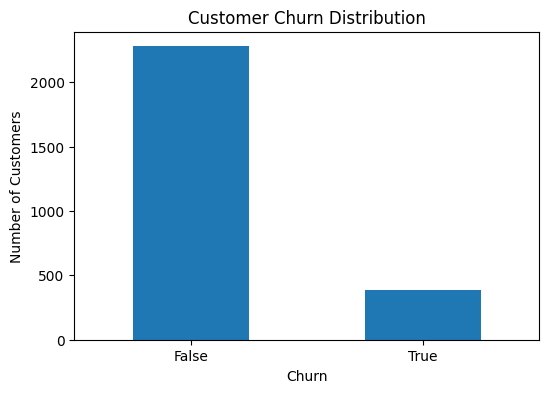

In [8]:
train_df['Churn'].value_counts().plot(
    kind='bar',
    figsize=(6, 4)
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

### Step-9: Separating Features and Target Variable

In [9]:
X_train = train_df.drop('Churn', axis=1)
y_train = train_df['Churn']

X_test = test_df.drop('Churn', axis=1)
y_test = test_df['Churn']

print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

print("Testing Features:", X_test.shape)
print("Testing Target:", y_test.shape)

Training Features: (2666, 19)
Training Target: (2666,)
Testing Features: (667, 19)
Testing Target: (667,)


### Step-10: Identifying Numerical and Categorical Features

In [10]:
categorical_features = [
    'State',
    'Area code',
    'International plan',
    'Voice mail plan'
]

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['State', 'Area code', 'International plan', 'Voice mail plan']

Numerical Features:
['Account length', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']


### Step-11: Creating the Data Preprocessing Pipeline

In [11]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


### Step-12: Applying Data Preprocessing

In [12]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Data After Preprocessing:",
      X_train_processed.shape)

print("Testing Data After Preprocessing:",
      X_test_processed.shape)

Training Data After Preprocessing: (2666, 73)
Testing Data After Preprocessing: (667, 73)


### Step-13: Building and Training the Logistic Regression Model

In [13]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_processed, y_train)
print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


### Step-14: Making Predictions

In [14]:
y_pred = model.predict(X_test_processed)
y_prob = model.predict_proba(X_test_processed)[:, 1]

print("Actual Values:")
print(y_test.head(10).tolist())

print("\nPredicted Values:")
print(y_pred[:10])

print("\nChurn Probabilities:")
print(y_prob[:10])

Actual Values:
[False, True, True, False, False, False, False, True, False, False]

Predicted Values:
[False False  True False False False False False False False]

Churn Probabilities:
[0.14368741 0.16069793 0.71537421 0.05429099 0.01963723 0.00588233
 0.31193907 0.27511641 0.04662146 0.08189904]


### Step-15: Analyzing Model Coefficients

In [15]:
feature_names = preprocessor.get_feature_names_out()

coefficients = model.coef_[0]

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coefficient_df = coefficient_df.sort_values(
    by='Coefficient',
    ascending=False
)

print(coefficient_df.to_string(index=False))

                    Feature  Coefficient
cat__International plan_Yes     1.074413
              cat__State_TX     1.034059
              cat__State_SC     0.942446
              cat__State_MT     0.834413
    cat__Voice mail plan_No     0.802958
              cat__State_MS     0.714116
num__Customer service calls     0.694923
              cat__State_NJ     0.673933
              cat__State_ME     0.632212
              cat__State_WA     0.575588
              cat__State_MI     0.551703
              cat__State_NH     0.532570
              cat__State_CA     0.502537
              cat__State_PA     0.473018
              cat__State_MN     0.455965
              cat__State_CT     0.427375
              cat__State_NY     0.396585
              cat__State_NV     0.352122
      num__Total day charge     0.350255
     num__Total day minutes     0.349537
 num__Number vmail messages     0.340341
              cat__State_MA     0.332222
              cat__State_MD     0.274667
              ca

### Step-16: Calculating Odds Ratios

In [16]:
odds_ratios = np.exp(model.coef_[0])

odds_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model.coef_[0],
    'Odds Ratio': odds_ratios
})

odds_df = odds_df.sort_values(
    by='Odds Ratio',
    ascending=False
)

print(odds_df.to_string(index=False))

                    Feature  Coefficient  Odds Ratio
cat__International plan_Yes     1.074413    2.928273
              cat__State_TX     1.034059    2.812459
              cat__State_SC     0.942446    2.566250
              cat__State_MT     0.834413    2.303462
    cat__Voice mail plan_No     0.802958    2.232134
              cat__State_MS     0.714116    2.042381
num__Customer service calls     0.694923    2.003555
              cat__State_NJ     0.673933    1.961938
              cat__State_ME     0.632212    1.881768
              cat__State_WA     0.575588    1.778176
              cat__State_MI     0.551703    1.736207
              cat__State_NH     0.532570    1.703303
              cat__State_CA     0.502537    1.652909
              cat__State_PA     0.473018    1.604831
              cat__State_MN     0.455965    1.577694
              cat__State_CT     0.427375    1.533228
              cat__State_NY     0.396585    1.486739
              cat__State_NV     0.352122    1.

### Step-17: Evaluating Model Performance

In [17]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label=True)

recall = recall_score(y_test, y_pred, pos_label=True)

f1 = f1_score(y_test, y_pred, pos_label=True)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.856071964017991
Precision: 0.4888888888888889
Recall: 0.23157894736842105
F1 Score: 0.3142857142857143


### Step-18: Generating the Classification Report

In [18]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.88      0.96      0.92       572
        True       0.49      0.23      0.31        95

    accuracy                           0.86       667
   macro avg       0.69      0.60      0.62       667
weighted avg       0.83      0.86      0.83       667



### Step-19: Visualizing the Confusion Matrix

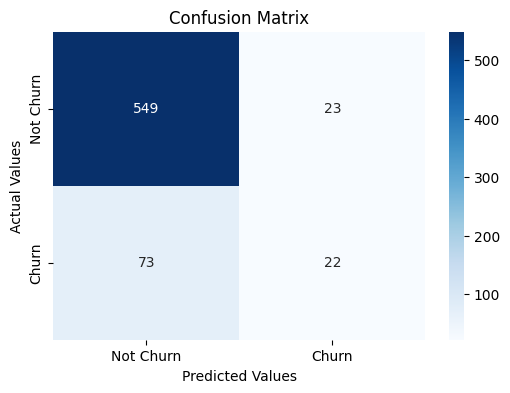

In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churn', 'Churn'],
    yticklabels=['Not Churn', 'Churn']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")

plt.show()

### Step-20: Plotting the ROC Curve

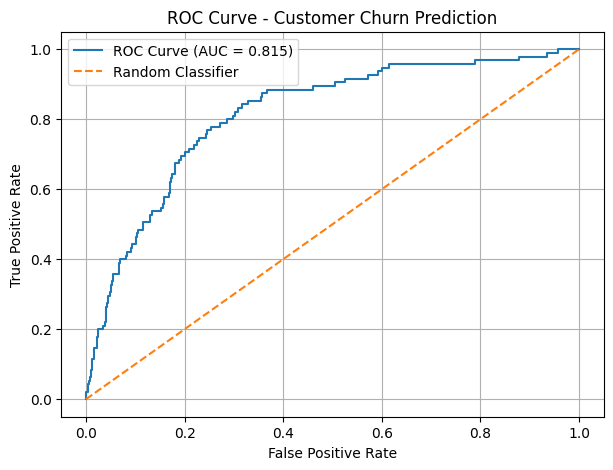

ROC-AUC Score: 0.814850938535149


In [20]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob,
    pos_label=True
)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'ROC Curve (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")

plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC Score:", roc_auc)

### Step-21: Visualizing Important Features

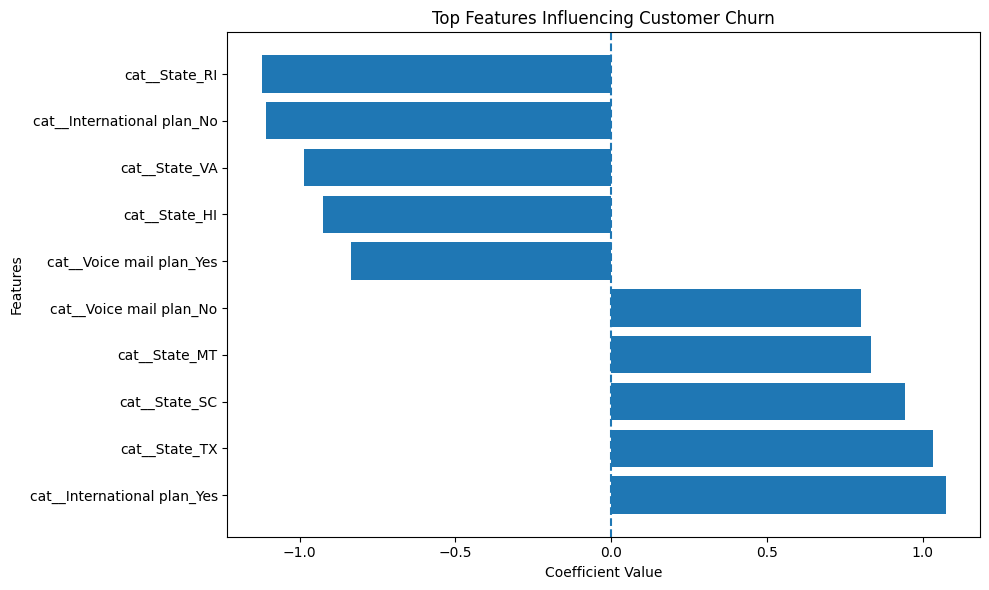

In [21]:
top_features = pd.concat([
    coefficient_df.head(5),
    coefficient_df.tail(5)
])

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.title("Top Features Influencing Customer Churn")

plt.axvline(x=0, linestyle='--')
plt.tight_layout()
plt.show()